# Capítulo 2. Ecuaciones de primer orden
## Sección 2.7.1. Contracción $L^1$, existencia y unicidad

**Fuente principal:** página 11 de `Ecuacione Lineales De Primer Orden.pdf`.

Se estudia la ley de conservación escalar

$$
u_t+f(u)_x=0,
\qquad
x\in\mathbb{R},
\quad
t>0,
$$

con dato inicial

$$
u(x,0)=u_0(x).
$$

### Objetivos

Al terminar esta sección se deberá poder:

1. formular la contracción en la norma $L^1$;
2. explicar por qué dicha contracción implica unicidad;
3. definir las entropías de Kružkov;
4. formular la desigualdad de Kato para dos soluciones;
5. demostrar rigurosamente la contracción global y su versión local;
6. deducir estabilidad continua y preservación del orden;
7. enunciar el teorema general de existencia de soluciones entrópicas;
8. interpretar numéricamente la disminución de la distancia entre dos soluciones.

La solución explícita del problema de Riemann se reserva para el notebook siguiente.

La escena Manim queda preparada en resolución $2560\times1440$ y $120$ fps. No se ejecuta ni se compila durante la generación.

### Ejemplo gráfico complementario · Distancia entre dos choques

Las curvas discrepan sólo en una franja de ancho $0.4$ y altura $2$. La distancia $L^1$ es el área $0.8$. Si ambos choques avanzan a la misma velocidad, esa área permanece constante aunque un observador fijo pueda medir una discrepancia de $2$. La palabra «contracción» permite la igualdad.


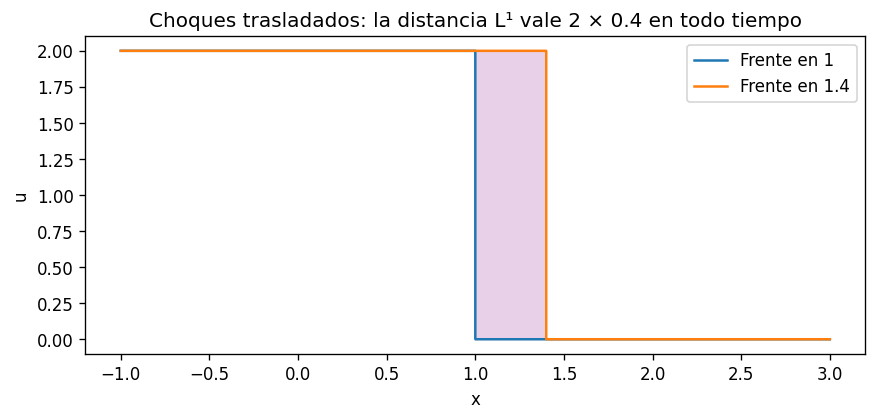

In [1]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7.4,3.6))
x=np.linspace(-1,3,801)
for posicion in [1,1.4]:
    ax.step(x,np.where(x<posicion,2,0),where="post",label=f"Frente en {posicion:g}")
ax.fill_between([1,1.4],0,2,alpha=0.18,color="purple")
ax.set(xlabel="x",ylabel="u",title="Choques trasladados: la distancia L¹ vale 2 × 0.4 en todo tiempo")
ax.legend()
fig.tight_layout()
plt.show()

# Fuente manuscrita

> **Fuente visual no incluida en el repositorio:** Página 11 de las notas. Referencia original: `assets/notas_pagina_11.png`.

> **Criterio editorial.** La página 11 contiene el teorema de contracción y su corolario de unicidad. La formulación general con entropías de Kružkov y la existencia por viscosidad evanescente se presentan como **Complemento** o **Resultado añadido**, pues no aparecen desarrolladas en las notas.

# 2.7.1. Transcripción organizada de las notas

En la página 11 se considera un flujo

$$
f\in C^2(\mathbb{R})
$$

estrictamente convexo, con

$$
f''(u)\geq\delta>0.
$$

Sean $u$ y $v$ dos soluciones por pedazos de clase $C^1$ y entrópicas de

$$
u_t+f(u)_x=0
$$

y

$$
v_t+f(v)_x=0,
$$

con datos iniciales $u_0$ y $v_0$.

Las notas afirman que

$$
t
\longmapsto
\lVert u(\cdot,t)-v(\cdot,t)\rVert_{L^1(\mathbb{R})}
$$

es una función no creciente.

Equivalentemente,

$$
\boxed{
\lVert u(\cdot,t)-v(\cdot,t)\rVert_{L^1(\mathbb{R})}
\leq
\lVert u_0-v_0\rVert_{L^1(\mathbb{R})}
}.
$$

Como corolario, si dos soluciones entrópicas tienen el mismo dato inicial,

$$
u_0=v_0,
$$

entonces

$$
u=v.
$$

Por tanto, dentro de la clase considerada en las notas, la solución entrópica es única.

# 2.7.2. Aclaraciones sobre las hipótesis

## Aclaración 2.7.1 — Integrabilidad de la diferencia

Para que la norma global tenga sentido se supone

$$
u_0-v_0\in L^1(\mathbb{R}).
$$

No es necesario que cada dato pertenezca por separado a $L^1(\mathbb{R})$. Por ejemplo, ambos pueden tender al mismo estado constante cuando

$$
|x|\longrightarrow\infty.
$$

## Aclaración 2.7.2 — Convexidad y contracción

La convexidad estricta es esencial en las notas para caracterizar los choques mediante Lax y Oleinik.

Sin embargo, el teorema general de contracción de Kružkov vale para cualquier flujo localmente Lipschitz:

$$
f\in C^1(\mathbb{R}).
$$

La contracción proviene de la estructura escalar de la ley de conservación y de la familia completa de desigualdades entrópicas.

## Aclaración 2.7.3 — Representantes temporales

Una solución entrópica admite un representante tal que

$$
u\in C\bigl([0,T];L^1_{\mathrm{loc}}(\mathbb{R})\bigr).
$$

De esta manera, la condición inicial y la desigualdad de contracción pueden interpretarse para todo tiempo.

# 2.7.3. Entropías de Kružkov

## Definición 2.7.4 — Par entrópico de Kružkov

Para cada constante $k\in\mathbb{R}$ se define

$$
\eta_k(u)=|u-k|
$$

y

$$
q_k(u)
=
\operatorname{sgn}(u-k)
\bigl(f(u)-f(k)\bigr).
$$

Formalmente,

$$
q_k'(u)
=
\eta_k'(u)f'(u)
$$

en los puntos donde $u\neq k$.

## Definición 2.7.5 — Solución entrópica de Kružkov

Sea

$$
u_0\in L^\infty(\mathbb{R})
$$

y sea

$$
u\in L^\infty
\bigl(\mathbb{R}\times(0,T)\bigr).
$$

Se dice que $u$ es una solución entrópica de Kružkov si, para todo $k\in\mathbb{R}$ y toda función no negativa

$$
\varphi\in C_c^\infty
\bigl(\mathbb{R}\times[0,T)\bigr),
$$

se cumple

$$
\int_0^T
\int_{\mathbb{R}}
\left[
|u-k|\varphi_t
+
\operatorname{sgn}(u-k)
\bigl(f(u)-f(k)\bigr)\varphi_x
\right]
\,dx\,dt
+
\int_{\mathbb{R}}
|u_0-k|\varphi(x,0)\,dx
\geq0.
$$

## Observación 2.7.6 — Relación con la formulación débil

Al combinar las desigualdades para valores grandes positivos y negativos de $k$ se recupera la ley de conservación en el sentido débil.

La desigualdad entrópica contiene información adicional: permite disipación en los choques, pero excluye discontinuidades expansivas.

# 2.7.4. Desigualdad de Kato

**Complemento · De una medida local al control global.** El valor absoluto de $u-v$ mide cuánto habría que agregar o quitar para igualar dos perfiles sin cancelaciones de signo. La desigualdad de Kato lo trata como una densidad con un flujo relativo. Al integrar sobre una región, el único posible aporte positivo viene del borde. En la recta, con diferencia inicial integrable y estados acotados, la cota del flujo y el paso a intervalos crecientes llevan al control global. Si la distancia inicial vale cero, queda cero en todo tiempo de la evolución entrópica.


## Teorema 2.7.7 — Desigualdad de Kato para dos soluciones

Sean $u$ y $v$ dos soluciones entrópicas acotadas de

$$
w_t+f(w)_x=0.
$$

Entonces, en el sentido de distribuciones,

$$
\boxed{
\partial_t|u-v|
+
\partial_x
\left[
\operatorname{sgn}(u-v)
\bigl(f(u)-f(v)\bigr)
\right]
\leq0
}.
$$

Equivalentemente, para toda función no negativa

$$
\phi\in C_c^\infty
\bigl(\mathbb{R}\times(0,T)\bigr),
$$

se cumple

$$
\int_0^T
\int_{\mathbb{R}}
\left[
|u-v|\phi_t
+
\operatorname{sgn}(u-v)
\bigl(f(u)-f(v)\bigr)\phi_x
\right]
\,dx\,dt
\geq0.
$$

## Demostración guiada

La demostración utiliza el método de duplicación de variables.

### Paso 1. Desigualdad para $u$

En la desigualdad entrópica de $u$ se sustituye formalmente la constante $k$ por

$$
v(y,s).
$$

Las variables $(y,s)$ se mantienen inicialmente como parámetros.

### Paso 2. Desigualdad para $v$

En la desigualdad entrópica de $v$ se toma

$$
k=u(x,t).
$$

### Paso 3. Función de prueba acoplada

Se elige

$$
\Phi_\varepsilon(x,t,y,s)
=
\phi\left(
\frac{x+y}{2},
\frac{t+s}{2}
\right)
\rho_\varepsilon(x-y)
\theta_\varepsilon(t-s),
$$

donde $\rho_\varepsilon$ y $\theta_\varepsilon$ son aproximaciones suaves de la identidad.

### Paso 4. Suma de las desigualdades

Al sumar las desigualdades de $u$ y $v$, los términos que contienen derivadas de

$$
\rho_\varepsilon(x-y)
$$

y

$$
\theta_\varepsilon(t-s)
$$

se cancelan por simetría.

Quedan términos en los que las derivadas actúan sobre la función macroscópica $\phi$.

### Paso 5. Límite diagonal

Al hacer

$$
\varepsilon\longrightarrow0,
$$

las aproximaciones de la identidad fuerzan

$$
y\longrightarrow x
$$

y

$$
s\longrightarrow t.
$$

La continuidad de las traslaciones en $L^1_{\mathrm{loc}}$ permite obtener

$$
\int
\int
\left[
|u-v|\phi_t
+
\operatorname{sgn}(u-v)
\bigl(f(u)-f(v)\bigr)\phi_x
\right]
\,dx\,dt
\geq0.
$$

> **Complemento.** La justificación completa del paso al límite usa truncamiento, Fubini, convergencia dominada y la continuidad de traslaciones en espacios $L^1_{\mathrm{loc}}$. La estructura esencial es la cancelación producida por la prueba simétrica.


# 2.7.5. Cota del flujo relativo

## Lema 2.7.8 — Control lipschitziano

Supongamos

$$
|u|\leq M
$$

y

$$
|v|\leq M.
$$

Definamos

$$
L_M
=
\max_{|z|\leq M}|f'(z)|.
$$

Entonces

$$
\left|
\operatorname{sgn}(u-v)
\bigl(f(u)-f(v)\bigr)
\right|
\leq
L_M|u-v|.
$$

### Demostración

Por el teorema del valor medio,

$$
f(u)-f(v)
=
f'(\xi)(u-v)
$$

para algún $\xi$ entre $u$ y $v$.

Como

$$
|\xi|\leq M,
$$

se obtiene

$$
|f(u)-f(v)|
\leq
L_M|u-v|.
$$

# 2.7.6. Contracción global en $L^1$

## Teorema 2.7.9 — Contracción $L^1$

Sean $u$ y $v$ soluciones entrópicas de Kružkov con datos $u_0$ y $v_0$. Supongamos

$$
u_0-v_0\in L^1(\mathbb{R}).
$$

Entonces, para todo $t\geq0$,

$$
\boxed{
\lVert u(\cdot,t)-v(\cdot,t)\rVert_{L^1(\mathbb{R})}
\leq
\lVert u_0-v_0\rVert_{L^1(\mathbb{R})}
}.
$$

### Demostración

Definimos

$$
W(x,t)=|u(x,t)-v(x,t)|
$$

y

$$
Q(x,t)
=
\operatorname{sgn}(u-v)
\bigl(f(u)-f(v)\bigr).
$$

La desigualdad de Kato afirma

$$
W_t+Q_x\leq0
$$

en distribuciones.

Sea $\chi_R\in C_c^\infty(\mathbb{R})$ tal que

$$
0\leq\chi_R\leq1,
$$

$$
\chi_R=1
\quad
\text{en }[-R,R],
$$

y

$$
|\chi_R'|\leq\frac{C}{R}.
$$

Integramos la desigualdad de Kato entre los tiempos $\tau$ y $t$ usando una aproximación suave del indicador temporal. Resulta

$$
\int_{\mathbb{R}}
W(x,t)\chi_R(x)\,dx
\leq
\int_{\mathbb{R}}
W(x,\tau)\chi_R(x)\,dx
+
\int_\tau^t
\int_{\mathbb{R}}
Q(x,s)\chi_R'(x)
\,dx\,ds.
$$

Por el Lema 2.7.8,

$$
|Q|\leq L_MW.
$$

El último término está soportado donde $\chi_R'$ no se anula. Por tanto,

$$
\left|
\int_\tau^t
\int_{\mathbb{R}}
Q\chi_R'
\,dx\,ds
\right|
\leq
\frac{CL_M}{R}
\int_\tau^t
\int_{\{R\leq|x|\leq2R\}}
W(x,s)
\,dx\,ds.
$$

Al hacer

$$
R\longrightarrow\infty,
$$

el término de frontera desaparece. Se obtiene

$$
\int_{\mathbb{R}}
W(x,t)\,dx
\leq
\int_{\mathbb{R}}
W(x,\tau)\,dx.
$$

Finalmente hacemos

$$
\tau\longrightarrow0^+.
$$

La continuidad de la traza inicial en $L^1_{\mathrm{loc}}$, junto con la integrabilidad de $u_0-v_0$, da

$$
\int_{\mathbb{R}}
|u(x,t)-v(x,t)|\,dx
\leq
\int_{\mathbb{R}}
|u_0(x)-v_0(x)|\,dx.
$$

## Corolario 2.7.10 — Monotonía temporal

La función

$$
D(t)
=
\lVert u(\cdot,t)-v(\cdot,t)\rVert_{L^1(\mathbb{R})}
$$

es no creciente.

# 2.7.7. Contracción local y velocidad finita

## Proposición 2.7.11 — Contracción dentro de un cono

Sean $u$ y $v$ soluciones acotadas por $M$ y sea

$$
L_M=\max_{|z|\leq M}|f'(z)|.
$$

Entonces, para todo $R>0$ y $t\geq0$,

$$
\int_{-R}^{R}
|u(x,t)-v(x,t)|
\,dx
\leq
\int_{-R-L_Mt}^{R+L_Mt}
|u_0(x)-v_0(x)|
\,dx.
$$

## Interpretación

La información puede propagarse, como máximo, con velocidad

$$
L_M.
$$

Para conocer la diferencia entre las soluciones dentro de $[-R,R]$ al tiempo $t$, basta conocer la diferencia inicial dentro del intervalo ampliado

$$
[-R-L_Mt,R+L_Mt].
$$

## Idea de la demostración

En la desigualdad de Kato se emplea una función de prueba que aproxima el indicador del cono retrógrado

$$
|x|\leq R+L_M(t-s).
$$

La frontera lateral se mueve con velocidad $L_M$. La cota

$$
|Q|\leq L_MW
$$

garantiza que el flujo relativo no entra al cono más rápidamente que su frontera.

# 2.7.8. Consecuencias de la contracción

## Corolario 2.7.12 — Unicidad

Si

$$
u_0=v_0
$$

casi en todas partes, entonces

$$
u(x,t)=v(x,t)
$$

casi en todas partes para todo $t\geq0$.

### Demostración

La contracción da

$$
\lVert u(\cdot,t)-v(\cdot,t)\rVert_{L^1}
\leq0.
$$

Por tanto,

$$
u(\cdot,t)=v(\cdot,t)
$$

casi en todas partes.

## Corolario 2.7.13 — Dependencia continua respecto del dato inicial

El operador de evolución

$$
S_tu_0=u(\cdot,t)
$$

satisface

$$
\lVert S_tu_0-S_tv_0\rVert_{L^1}
\leq
\lVert u_0-v_0\rVert_{L^1}.
$$

Por tanto, el semigrupo entrópico es no expansivo en $L^1$.

## Corolario 2.7.14 — Preservación del orden

Si

$$
u_0\leq v_0
$$

casi en todas partes, entonces

$$
u(x,t)\leq v(x,t)
$$

casi en todas partes para todo $t\geq0$.

## Demostración

Se aplica la versión positiva de la desigualdad de Kato a

$$
(u-v)^+
=
\max\{u-v,0\}.
$$

Se obtiene

$$
\int_{\mathbb{R}}
(u(x,t)-v(x,t))^+
\,dx
\leq
\int_{\mathbb{R}}
(u_0(x)-v_0(x))^+
\,dx.
$$

El término derecho es cero.

# 2.7.9. Existencia de soluciones entrópicas

## Resultado añadido 2.7.15 — Teorema de existencia y unicidad de Kružkov

Sea

$$
f\in C^1(\mathbb{R})
$$

y sea

$$
u_0\in L^\infty(\mathbb{R}).
$$

Entonces existe una única solución entrópica de Kružkov

$$
u\in L^\infty
\bigl(\mathbb{R}\times(0,\infty)\bigr)
$$

del problema de Cauchy

$$
\begin{cases}
u_t+f(u)_x=0,\\
u(x,0)=u_0(x).
\end{cases}
$$

Además,

$$
\lVert u(\cdot,t)\rVert_{L^\infty}
\leq
\lVert u_0\rVert_{L^\infty},
$$

y

$$
u\in C
\bigl([0,\infty);L^1_{\mathrm{loc}}(\mathbb{R})\bigr).
$$

Si dos datos tienen diferencia en $L^1$, sus soluciones satisfacen la contracción global.

## Comentario 2.7.16 — Qué aporta la página 11 y qué se añade

La página 11 contiene la parte de estabilidad y unicidad para soluciones por pedazos suaves y entrópicas.

La existencia general para datos en $L^\infty$ no está demostrada en las notas. Se añade aquí para cerrar el subtema de existencia y unicidad del temario.

## Hoja de ruta de la existencia por viscosidad evanescente

### Paso 1. Problema parabólico regularizado

Se resuelve

$$
u_t^\varepsilon
+
f(u^\varepsilon)_x
=
\varepsilon u_{xx}^\varepsilon
$$

con dato inicial suavizado

$$
u_0^\varepsilon
=
u_0*\rho_\varepsilon.
$$

### Paso 2. Principio del máximo

La solución viscosa satisface

$$
\lVert u^\varepsilon(\cdot,t)\rVert_{L^\infty}
\leq
\lVert u_0\rVert_{L^\infty}.
$$

### Paso 3. Desigualdades entrópicas aproximadas

Para toda entropía convexa $\eta$,

$$
\eta(u^\varepsilon)_t
+
q(u^\varepsilon)_x
\leq
\varepsilon
\eta(u^\varepsilon)_{xx}
$$

en distribuciones.

### Paso 4. Compacidad

Las cotas uniformes y las estimaciones de traslación permiten extraer una sucesión

$$
u^{\varepsilon_j}
$$

que converge a una función $u$ en $L^1_{\mathrm{loc}}$.

Para datos de variación acotada, esta compacidad se obtiene directamente mediante cotas de variación total. Para datos generales acotados se utiliza aproximación y estabilidad.

### Paso 5. Paso al límite

Al hacer

$$
\varepsilon_j\longrightarrow0,
$$

las desigualdades viscosas producen las desigualdades entrópicas de Kružkov.

### Paso 6. Unicidad

La contracción $L^1$ demuestra que cualquier límite entrópico coincide con cualquier otro. Así, toda la familia viscosa converge al mismo límite.

# 2.7.10. Comparación numérica

Se aproximan dos soluciones entrópicas de Burgers mediante el esquema conservativo de Godunov.

Los datos son

$$
u_0(x)
=
\begin{cases}
1, & -3<x<-1,\\
0, & \text{en otro caso},
\end{cases}
$$

y

$$
v_0(x)
=
\begin{cases}
1, & -3<x<-2,\\
1, & -\frac32<x<-\frac12,\\
0, & \text{en otro caso}.
\end{cases}
$$

Ambos datos tienen la misma masa, pero distribuciones espaciales diferentes.

La animación muestra:

- ambos perfiles numéricos;
- el área correspondiente a $|u-v|$;
- la distancia discreta
  $$
  D_h(t)
  =
  \sum_j|u_j(t)-v_j(t)|\Delta x;
  $$
- la gráfica de $D_h(t)$.

El esquema de Godunov es monótono y selecciona la solución entrópica. La distancia discreta no aumenta y disminuye cuando las ondas interactúan.

Los perfiles iniciales permanecen visibles durante cuatro segundos antes de iniciar la evolución.

In [ ]:
import os
import shutil
import tempfile
import uuid
from pathlib import Path

def miktex_candidates():
    candidates = []
    for base in (
        os.environ.get("LOCALAPPDATA"),
        os.environ.get("ProgramFiles"),
        os.environ.get("ProgramFiles(x86)"),
    ):
        if not base:
            continue
        root = Path(base)
        candidates.extend([
            root / "Programs" / "MiKTeX" / "miktex" / "bin" / "x64",
            root / "Programs" / "MiKTeX" / "miktex" / "bin",
            root / "MiKTeX" / "miktex" / "bin" / "x64",
            root / "MiKTeX" / "miktex" / "bin",
        ])
    return candidates

for candidate in miktex_candidates():
    if candidate.exists():
        os.environ["PATH"] = (
            str(candidate)
            + os.pathsep
            + os.environ.get("PATH", "")
        )

latex_exe = shutil.which("latex")
dvisvgm_exe = shutil.which("dvisvgm")

if latex_exe is None or dvisvgm_exe is None:
    raise RuntimeError(
        "No se encontraron latex.exe y dvisvgm.exe. "
        "Abre MiKTeX Console, completa la instalación y reinicia el kernel."
    )

from manim import config, __version__ as manim_version

TEX_RUNTIME_DIR = (
    Path(tempfile.gettempdir())
    / f"manim_tex_contraccion_l1_{os.getpid()}_{uuid.uuid4().hex[:10]}"
)
TEX_RUNTIME_DIR.mkdir(parents=True, exist_ok=True)

config.no_latex_cleanup = True
config.tex_dir = str(TEX_RUNTIME_DIR)
config.media_embed = True
config.media_width = "100%"

print(f"Manim Community: {manim_version}")
print("latex   :", latex_exe)
print("dvisvgm :", dvisvgm_exe)
print("TeX dir :", TEX_RUNTIME_DIR)
print("Render preparado: 2560×1440, 120 fps")
print("La animación no ha sido compilada.")

In [ ]:
%%manim -v WARNING -r 2560,1440 --fps 120 ContraccionL1Godunov

from manim import *
import numpy as np

config.no_latex_cleanup = True
config.tex_dir = str(TEX_RUNTIME_DIR)
config.media_embed = True
config.media_width = "100%"


# ============================================================
# 1. Aproximación entrópica de Burgers mediante Godunov
# ============================================================

X_MIN = -6.0
X_MAX = 6.0
N_X = 720
T_FINAL = 3.0
N_SNAPSHOTS = 181
CFL = 0.44

X_GRID = np.linspace(X_MIN, X_MAX, N_X)
DX = X_GRID[1] - X_GRID[0]
SNAP_TIMES = np.linspace(0.0, T_FINAL, N_SNAPSHOTS)


def burgers_flux(u):
    return 0.5 * u**2


def godunov_flux(left, right):
    flux_left = burgers_flux(left)
    flux_right = burgers_flux(right)
    result = np.empty_like(left)

    rarefaction = left <= right

    mask = rarefaction & (left >= 0.0)
    result[mask] = flux_left[mask]

    mask = rarefaction & (right <= 0.0)
    result[mask] = flux_right[mask]

    mask = rarefaction & (left < 0.0) & (right > 0.0)
    result[mask] = 0.0

    shock = ~rarefaction
    result[shock] = np.maximum(
        flux_left[shock],
        flux_right[shock],
    )

    return result


def advance_godunov(initial_data):
    state = initial_data.astype(float).copy()
    snapshots = [state.copy()]
    current_time = 0.0
    next_snapshot = 1

    while next_snapshot < N_SNAPSHOTS:
        max_speed = max(
            float(np.max(np.abs(state))),
            1.0e-10,
        )

        dt_cfl = CFL * DX / max_speed
        dt_target = (
            SNAP_TIMES[next_snapshot]
            - current_time
        )
        dt = min(dt_cfl, dt_target)

        ghosted = np.concatenate(
            ([state[0]], state, [state[-1]])
        )

        numerical_flux = godunov_flux(
            ghosted[:-1],
            ghosted[1:],
        )

        state = (
            state
            - dt / DX
            * (
                numerical_flux[1:]
                - numerical_flux[:-1]
            )
        )

        current_time += dt

        if (
            current_time
            >= SNAP_TIMES[next_snapshot] - 1.0e-12
        ):
            snapshots.append(state.copy())
            next_snapshot += 1

    return np.asarray(snapshots)


U0 = (
    (X_GRID > -3.0)
    & (X_GRID < -1.0)
).astype(float)

V0 = (
    (
        (X_GRID > -3.0)
        & (X_GRID < -2.0)
    )
    |
    (
        (X_GRID > -1.5)
        & (X_GRID < -0.5)
    )
).astype(float)

U_SNAPSHOTS = advance_godunov(U0)
V_SNAPSHOTS = advance_godunov(V0)

L1_VALUES = np.trapezoid(
    np.abs(U_SNAPSHOTS - V_SNAPSHOTS),
    X_GRID,
    axis=1,
)


# ============================================================
# 2. Escena
# ============================================================

class ContraccionL1Godunov(Scene):
    def construct(self):
        self.camera.background_color = "#0B1020"

        color_u = ORANGE
        color_v = TEAL_C
        color_distance = YELLOW_C
        color_area = BLUE_B

        title = Text(
            "Contracción L¹ para soluciones entrópicas",
            font_size=40,
            weight=BOLD,
            color=WHITE,
        ).to_edge(UP, buff=0.18)

        equation = MathTex(
            r"u_t+\left(\frac{u^2}{2}\right)_x=0",
            r"\qquad",
            r"\|u(t)-v(t)\|_{L^1}\leq\|u_0-v_0\|_{L^1}",
            font_size=33,
        ).next_to(title, DOWN, buff=0.12)
        equation[2].set_color(color_distance)

        self.play(
            FadeIn(title, shift=0.10 * DOWN),
            Write(equation),
            run_time=1.7,
        )

        time = ValueTracker(0.0)

        profile_axes = Axes(
            x_range=[X_MIN, X_MAX, 2],
            y_range=[0, 1.35, 0.25],
            x_length=7.1,
            y_length=4.8,
            tips=False,
            axis_config={
                "stroke_width": 2,
                "include_numbers": True,
                "font_size": 19,
            },
        ).move_to(3.15 * LEFT + 0.55 * DOWN)

        distance_axes = Axes(
            x_range=[0, T_FINAL, 0.5],
            y_range=[
                0,
                1.10 * float(np.max(L1_VALUES)),
                0.2,
            ],
            x_length=5.3,
            y_length=4.8,
            tips=False,
            axis_config={
                "stroke_width": 2,
                "include_numbers": True,
                "font_size": 19,
            },
        ).move_to(3.75 * RIGHT + 0.55 * DOWN)

        profile_labels = profile_axes.get_axis_labels(
            MathTex(r"x", font_size=27),
            MathTex(r"u,v", font_size=27),
        )

        distance_labels = distance_axes.get_axis_labels(
            MathTex(r"t", font_size=27),
            MathTex(r"D_h(t)", font_size=27),
        )

        profile_heading = Text(
            "Perfiles aproximados",
            font_size=27,
            weight=SEMIBOLD,
        ).next_to(profile_axes, UP, buff=0.14)

        distance_heading = Text(
            "Distancia discreta L¹",
            font_size=27,
            weight=SEMIBOLD,
        ).next_to(distance_axes, UP, buff=0.14)

        def snapshot_index():
            return int(
                np.clip(
                    np.searchsorted(
                        SNAP_TIMES,
                        time.get_value(),
                        side="right",
                    )
                    - 1,
                    0,
                    N_SNAPSHOTS - 1,
                )
            )

        sampled_indices = np.arange(
            0,
            N_X,
            3,
            dtype=int,
        )

        def profile_curve(values, color):
            points = [
                profile_axes.c2p(
                    X_GRID[index],
                    values[index],
                )
                for index in sampled_indices
            ]

            curve = VMobject()
            curve.set_points_as_corners(points)
            curve.set_stroke(
                color=color,
                width=5,
            )
            return curve

        def difference_region():
            index = snapshot_index()
            u_values = U_SNAPSHOTS[index]
            v_values = V_SNAPSHOTS[index]

            upper_points = [
                profile_axes.c2p(
                    X_GRID[j],
                    max(u_values[j], v_values[j]),
                )
                for j in sampled_indices
            ]

            lower_points = [
                profile_axes.c2p(
                    X_GRID[j],
                    min(u_values[j], v_values[j]),
                )
                for j in sampled_indices[::-1]
            ]

            polygon = Polygon(
                *(upper_points + lower_points),
                stroke_width=0,
                fill_color=color_area,
                fill_opacity=0.18,
            )
            return polygon

        u_curve = always_redraw(
            lambda: profile_curve(
                U_SNAPSHOTS[snapshot_index()],
                color_u,
            )
        )

        v_curve = always_redraw(
            lambda: profile_curve(
                V_SNAPSHOTS[snapshot_index()],
                color_v,
            )
        )

        area_between = always_redraw(
            difference_region
        )

        legend = VGroup(
            VGroup(
                Line(
                    ORIGIN,
                    0.45 * RIGHT,
                    color=color_u,
                    stroke_width=5,
                ),
                MathTex(
                    r"u_h",
                    font_size=28,
                    color=color_u,
                ),
            ).arrange(RIGHT, buff=0.08),
            VGroup(
                Line(
                    ORIGIN,
                    0.45 * RIGHT,
                    color=color_v,
                    stroke_width=5,
                ),
                MathTex(
                    r"v_h",
                    font_size=28,
                    color=color_v,
                ),
            ).arrange(RIGHT, buff=0.08),
        ).arrange(RIGHT, buff=0.35)
        legend.next_to(profile_axes, DOWN, buff=0.15)

        full_distance_points = [
            distance_axes.c2p(t, d)
            for t, d in zip(
                SNAP_TIMES,
                L1_VALUES,
            )
        ]

        full_distance_curve = VMobject()
        full_distance_curve.set_points_as_corners(
            full_distance_points
        )
        full_distance_curve.set_stroke(
            color=GREY_B,
            width=3,
            opacity=0.45,
        )

        def partial_distance_curve():
            current_time = time.get_value()
            mask = SNAP_TIMES <= current_time

            selected_times = SNAP_TIMES[mask]
            selected_values = L1_VALUES[mask]

            if len(selected_times) < 2:
                selected_times = SNAP_TIMES[:2]
                selected_values = L1_VALUES[:2]

            points = [
                distance_axes.c2p(t, d)
                for t, d in zip(
                    selected_times,
                    selected_values,
                )
            ]

            curve = VMobject()
            curve.set_points_as_corners(points)
            curve.set_stroke(
                color=color_distance,
                width=5,
            )
            return curve

        distance_trace = always_redraw(
            partial_distance_curve
        )

        distance_dot = always_redraw(
            lambda: Dot(
                distance_axes.c2p(
                    time.get_value(),
                    float(
                        np.interp(
                            time.get_value(),
                            SNAP_TIMES,
                            L1_VALUES,
                        )
                    ),
                ),
                radius=0.075,
                color=color_distance,
            )
        )

        time_tex = MathTex(
            r"t=",
            font_size=29,
            color=GREEN_C,
        )

        time_number = DecimalNumber(
            0.0,
            num_decimal_places=2,
            font_size=29,
            color=GREEN_C,
        )
        time_number.add_updater(
            lambda mob: mob.set_value(
                time.get_value()
            )
        )

        distance_tex = MathTex(
            r"D_h(t)=",
            font_size=29,
            color=color_distance,
        )

        distance_number = DecimalNumber(
            float(L1_VALUES[0]),
            num_decimal_places=3,
            font_size=29,
            color=color_distance,
        )
        distance_number.add_updater(
            lambda mob: mob.set_value(
                float(
                    np.interp(
                        time.get_value(),
                        SNAP_TIMES,
                        L1_VALUES,
                    )
                )
            )
        )

        display = VGroup(
            VGroup(
                time_tex,
                time_number,
            ).arrange(RIGHT, buff=0.05),
            VGroup(
                distance_tex,
                distance_number,
            ).arrange(RIGHT, buff=0.05),
        ).arrange(
            DOWN,
            aligned_edge=LEFT,
            buff=0.08,
        ).move_to(0.20 * DOWN)

        monotonicity = MathTex(
            r"D_h(t_2)\leq D_h(t_1)",
            r"\qquad",
            r"t_2\geq t_1",
            font_size=29,
            color=color_distance,
        ).next_to(distance_axes, DOWN, buff=0.15)

        self.play(
            FadeIn(profile_axes),
            FadeIn(distance_axes),
            FadeIn(profile_labels),
            FadeIn(distance_labels),
            FadeIn(profile_heading),
            FadeIn(distance_heading),
            FadeIn(area_between),
            FadeIn(u_curve),
            FadeIn(v_curve),
            FadeIn(legend),
            Create(full_distance_curve),
            FadeIn(distance_trace),
            FadeIn(distance_dot),
            FadeIn(display),
            FadeIn(monotonicity),
            run_time=3.0,
        )

        # Los perfiles iniciales se observan antes de la dinámica.
        self.wait(4.0)

        self.play(
            time.animate.set_value(T_FINAL),
            run_time=12.0,
            rate_func=linear,
        )

        self.wait(2.0)

        time_number.clear_updaters()
        distance_number.clear_updaters()

        conclusion = VGroup(
            MathTex(
                r"D_h(0)=",
                f"{L1_VALUES[0]:.3f}",
                font_size=39,
            ),
            MathTex(
                r"D_h(T)=",
                f"{L1_VALUES[-1]:.3f}",
                font_size=39,
            ),
            MathTex(
                r"D_h(T)\leq D_h(0)",
                font_size=46,
                color=color_distance,
            ),
            Text(
                "Las interacciones no aumentan la distancia L¹",
                font_size=30,
                color=WHITE,
            ),
        ).arrange(DOWN, buff=0.26)

        conclusion_box = SurroundingRectangle(
            conclusion,
            color=BLUE_B,
            stroke_width=3,
            buff=0.38,
            corner_radius=0.12,
        )

        panel_objects = VGroup(
            profile_axes,
            distance_axes,
            profile_labels,
            distance_labels,
            profile_heading,
            distance_heading,
            area_between,
            u_curve,
            v_curve,
            legend,
            full_distance_curve,
            distance_trace,
            distance_dot,
            display,
            monotonicity,
            equation,
        )

        self.play(
            FadeOut(panel_objects),
            run_time=1.4,
        )

        self.play(
            FadeIn(conclusion_box),
            LaggedStart(
                *[Write(item) for item in conclusion],
                lag_ratio=0.18,
            ),
            run_time=3.5,
        )

        self.wait(3.0)

# 2.7.11. Ejercicios propuestos

## Ejercicio 2.7.1 — Del dato inicial a la unicidad

Sean $u$ y $v$ dos soluciones entrópicas con el mismo dato inicial. Utilice exclusivamente la contracción $L^1$ para demostrar que

$$
u=v
$$

casi en todas partes.

Explique por qué no basta saber que ambas funciones son soluciones débiles.

## Ejercicio 2.7.2 — Cota del flujo relativo

Sean $u$ y $v$ acotadas por $M$. Demuestre

$$
\left|
\operatorname{sgn}(u-v)
\bigl(f(u)-f(v)\bigr)
\right|
\leq
L_M|u-v|,
$$

donde

$$
L_M=\max_{|z|\leq M}|f'(z)|.
$$

Determine $L_M$ para Burgers cuando

$$
|u|,|v|\leq A.
$$



# Revisión del avance respecto del temario

## Sección cubierta

Se completó **2.7.1. Contracción $L^1$, existencia y unicidad**:

- transcripción del teorema de la página 11;
- entropías de Kružkov;
- desigualdad de Kato;
- demostración guiada por duplicación de variables;
- contracción global en $L^1$;
- contracción local y velocidad finita;
- unicidad;
- dependencia continua;
- preservación del orden;
- estructura de semigrupo;
- teorema general de existencia;
- construcción por viscosidad evanescente;
- comparación numérica con Godunov;
- ejercicios tipo Examen General;
- escena Manim no compilada.

## Grado de exhaustividad

La estabilidad y la unicidad quedaron demostradas de manera completa a partir de la desigualdad de Kato.

La existencia general se presenta con un enunciado preciso y una hoja de ruta rigurosa. Una demostración completa de la compactación para datos meramente acotados requeriría desarrollar teoría adicional de compacidad y excedería el contenido manuscrito de esta sección.

## Relación con el temario oficial

La sección cierra el mecanismo de unicidad para soluciones entrópicas y prepara el estudio explícito del problema de Riemann para flujos convexos.

Este resultado es el fundamento para afirmar que las soluciones entrópicas obtenidas en los problemas históricos de Burgers y LWR son únicas.

## Siguiente notebook según el manifiesto

El siguiente pendiente es

`2.6.2_Problema_de_Riemann.ipynb`.

Aunque la numeración vuelve a 2.6.2, se conserva el orden explícito del manifiesto y de la cola del proyecto.